# DSR301m – Ablation Study: ACC có thực sự giúp không?
**Bước 3 của Reliability & Evaluation** (sau LOSO → Evaluation).

| Cấu hình | Đặc trưng | Số đặc trưng |
|---|---|---|
| **A** – Physiological-only | BVP + EDA + TEMP | 19 |
| **B** – Context-aware | BVP + EDA + TEMP + ACC | 25 |
| **C** – ACC-only *(chẩn đoán, không có trong paper)* | ACC | 6 |

Cùng giao thức LOSO 15-fold, cùng mô hình (XGBoost + Isotonic, fold hiệu chuẩn theo `INNER_CV`), cùng τ = 0.80, cùng θ_motion. Chỉ khác tập đặc trưng.

Cấu hình C để kiểm tra xem ACC có giúp vì làm "cổng bất định" hay chỉ vì **bản thân chuyển động đã tương quan với nhãn Stress** (trong WESAD, pha Stress có cử động tay nhiều hơn).

## 0. Cài đặt

In [1]:
!pip -q install xgboost

import os, time, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon
from sklearn.preprocessing import StandardScaler
from sklearn.calibration import CalibratedClassifierCV
from sklearn.model_selection import GroupKFold, StratifiedKFold
from sklearn.metrics import f1_score, accuracy_score
from xgboost import XGBClassifier
warnings.filterwarnings("ignore")

SEEDS = [42, 0, 1, 2, 3]         # seed đầu tiên = seed chính (dùng cho per-subject & bootstrap)
TAU_MAIN = 0.80
INNER_CV = "group"                # "group" (khuyến nghị) | "paper_cv3" | "random"  (xem notebook 01, mục 2 và 10)
RUN_ACC_ONLY = True               # cấu hình C (chẩn đoán)
B_BOOT = 1000
OUT = "results_ablation"; os.makedirs(OUT, exist_ok=True)

## 1. Nạp dữ liệu & đổi tên subject S1–S15

In [2]:
DATA_PATH = "../Dataset/wesad_wrist_features.csv" if os.path.exists("../Dataset/wesad_wrist_features.csv") else "wesad_wrist_features.csv"
if not os.path.exists(DATA_PATH):
    from google.colab import files
    files.upload()
df = pd.read_csv(DATA_PATH)
META  = ["subject_id", "time_start_sec", "time_end_sec", "label"]
FEATS = [c for c in df.columns if c not in META]
ACC_FEATS  = [c for c in FEATS if c.startswith("acc_")]
PHYS_FEATS = [c for c in FEATS if not c.startswith("acc_")]
# đổi tên S2..S17 (không có S12) -> S1..S15, giữ ID gốc
orig_ids = sorted(df.subject_id.unique(), key=lambda s: int(s[1:]))
id_map = {old: f"S{i+1}" for i, old in enumerate(orig_ids)}
df["subject_orig"] = df.subject_id
df["sid_num"] = df.subject_id.map(lambda s: int(s[1:]))
df["subject_id"] = df.subject_id.map(id_map)
df = df.sort_values(["sid_num", "time_start_sec"]).reset_index(drop=True)
SUBJECTS = [id_map[s] for s in orig_ids]
print("Physio:", len(PHYS_FEATS), "| ACC:", len(ACC_FEATS), "| Tổng:", len(FEATS))
assert len(PHYS_FEATS) == 19 and len(ACC_FEATS) == 6 and df.subject_id.nunique() == 15
FEAT_SETS = {"A: Physio-only": PHYS_FEATS, "B: Physio+ACC": FEATS}
if RUN_ACC_ONLY: FEAT_SETS["C: ACC-only"] = ACC_FEATS
y_all = df.label.values
g_all = df.subject_id.values
THETA = np.percentile(df.acc_mag_var, 80)       # ngưỡng vận động mạnh: KHÔNG phụ thuộc cấu hình
HM = (df.acc_mag_var.values >= THETA)
print(f"θ_motion = {THETA:.3f} | High-motion = {HM.mean()*100:.1f}% mẫu")


Saving wesad_wrist_features.csv to wesad_wrist_features.csv
Physio: 19 | ACC: 6 | Tổng: 25
θ_motion = 15.385 | High-motion = 20.0% mẫu


## 2. LOSO cho từng cấu hình × từng seed
Scaler và calibrator chỉ fit trên 14 subject train. Chỉ số θ_motion luôn tính từ `acc_mag_var` nên **Cấu hình A vẫn được đánh giá trên cùng tập "vận động mạnh"** dù không dùng ACC làm đặc trưng.

In [3]:
def inner_cv_splits(Xtr, ytr, gtr, mode=INNER_CV, seed=42):
    """Cách chia fold để HIỆU CHUẨN (Isotonic) bên trong 14 subject train.
    group     : GroupKFold theo subject  -> không rò rỉ giữa các cửa sổ chồng lắp, KHÔNG phụ thuộc thứ tự hàng (khuyến nghị)
    paper_cv3 : StratifiedKFold(3) không shuffle = cv=3 mặc định của sklearn -> chia theo khối liên tiếp, PHỤ THUỘC thứ tự hàng
    random    : StratifiedKFold(3, shuffle=True) -> các cửa sổ gần trùng nhau rơi vào cả hai phía -> hiệu chuẩn quá tự tin
    """
    if mode == "group":     return list(GroupKFold(n_splits=3).split(Xtr, ytr, groups=gtr))
    if mode == "paper_cv3": return list(StratifiedKFold(n_splits=3, shuffle=False).split(Xtr, ytr))
    if mode == "random":    return list(StratifiedKFold(n_splits=3, shuffle=True, random_state=seed).split(Xtr, ytr))
    raise ValueError(mode)

def make_xgb(seed):
    return XGBClassifier(n_estimators=100, max_depth=5, learning_rate=0.08, subsample=0.8,
                         eval_metric="logloss", random_state=seed, n_jobs=-1, verbosity=0)

def loso_proba(feats, seed):
    X = df[feats].values; P = np.zeros(len(df))
    for s in SUBJECTS:
        te, tr = (g_all == s), (g_all != s)
        sc = StandardScaler().fit(X[tr])
        Xs = sc.transform(X[tr])
        cal = CalibratedClassifierCV(make_xgb(seed), method="isotonic", cv=inner_cv_splits(Xs, y_all[tr], g_all[tr], INNER_CV, seed))
        cal.fit(Xs, y_all[tr])
        P[te] = cal.predict_proba(sc.transform(X[te]))[:, 1]
    return P

PROBA = {}                      # (cfg, seed) -> p_cal
t0 = time.time()
for seed in SEEDS:
    for cfg, feats in FEAT_SETS.items():
        PROBA[(cfg, seed)] = loso_proba(feats, seed)
        print(f"seed {seed:>2} | {cfg:<15} xong ({time.time()-t0:5.0f}s)")

S0 = SEEDS[0]
oof = df[["subject_id", "subject_orig", "time_start_sec", "label", "acc_mag_var"]].copy()
for cfg in FEAT_SETS: oof[f"p_{cfg[0]}"] = PROBA[(cfg, S0)]
oof.to_csv(f"{OUT}/oof_ablation_seed{S0}.csv", index=False)

seed 42 | A: Physio-only  xong (   49s)
seed 42 | B: Physio+ACC   xong (   69s)
seed 42 | C: ACC-only     xong (   77s)
seed  0 | A: Physio-only  xong (   88s)
seed  0 | B: Physio+ACC   xong (  102s)
seed  0 | C: ACC-only     xong (  107s)
seed  1 | A: Physio-only  xong (  119s)
seed  1 | B: Physio+ACC   xong (  133s)
seed  1 | C: ACC-only     xong (  140s)
seed  2 | A: Physio-only  xong (  151s)
seed  2 | B: Physio+ACC   xong (  165s)
seed  2 | C: ACC-only     xong (  171s)
seed  3 | A: Physio-only  xong (  182s)
seed  3 | B: Physio+ACC   xong (  195s)
seed  3 | C: ACC-only     xong (  200s)


## 3. Hàm đánh giá (giống notebook LOSO/Evaluation)

In [4]:
def ece_conf(y, p, M=10):
    conf = np.maximum(p, 1 - p); corr = ((p >= .5).astype(int) == y)
    b = np.minimum(((conf - .5) / .5 * M).astype(int), M - 1); e = 0.0
    for m in range(M):
        k = b == m
        if k.any(): e += k.mean() * abs(corr[k].mean() - conf[k].mean())
    return e

def far_motion(y, pred, hm, accepted=None):
    den = ((y == 0) & hm).sum()
    if den == 0: return np.nan
    acc = np.ones_like(y, bool) if accepted is None else accepted
    return ((pred == 1) & (y == 0) & hm & acc).sum() / den * 100

def metrics(y, p, hm, tau=TAU_MAIN):
    pred0 = (p >= .5).astype(int)
    acc = (p >= tau) | ((1 - p) >= tau); pred = (p >= tau).astype(int)
    r = dict(F1_full=f1_score(y, pred0, zero_division=0), ECE_full=ece_conf(y, p),
             FAR_full=far_motion(y, pred0, hm), Coverage=acc.mean()*100)
    if acc.sum():
        r.update(Sel_F1=f1_score(y[acc], pred[acc], zero_division=0),
                 Sel_F1_macro=f1_score(y[acc], pred[acc], average="macro", zero_division=0),
                 Sel_Acc=accuracy_score(y[acc], pred[acc]), ECE_sel=ece_conf(y[acc], p[acc]),
                 FAR_sel=far_motion(y, pred, hm, accepted=acc),
                 Cov_high=acc[hm].mean()*100 if hm.any() else np.nan,
                 Cov_low=acc[~hm].mean()*100)
    return r

def mean_std(df_):
    return df_.mean().round(4).astype(str) + " ± " + df_.std(ddof=1).round(4).astype(str)

## 4. Bảng chính: A vs B (trung bình ± độ lệch chuẩn qua các seed)

In [5]:
rows = []
for cfg in FEAT_SETS:
    for seed in SEEDS:
        r = metrics(y_all, PROBA[(cfg, seed)], HM); r.update(config=cfg, seed=seed); rows.append(r)
per_seed = pd.DataFrame(rows); per_seed.to_csv(f"{OUT}/ablation_per_seed.csv", index=False)

cols = ["Coverage", "Sel_F1", "Sel_F1_macro", "ECE_sel", "FAR_sel", "F1_full", "ECE_full", "FAR_full", "Cov_high", "Cov_low"]
tab_main = pd.DataFrame({cfg: mean_std(per_seed[per_seed.config == cfg][cols]) for cfg in FEAT_SETS}).T
tab_main.to_csv(f"{OUT}/ablation_main_table.csv")
print(f"τ = {TAU_MAIN} | {len(SEEDS)} seed | mean ± std qua seed")
display(tab_main)

# chênh lệch B - A theo từng seed
d = (per_seed[per_seed.config == "B: Physio+ACC"].set_index("seed")[cols]
     - per_seed[per_seed.config == "A: Physio-only"].set_index("seed")[cols])
print("Chênh lệch (B − A) qua các seed:")
display(pd.DataFrame({"mean": d.mean(), "std": d.std(ddof=1), "min": d.min(), "max": d.max()}).round(4))

τ = 0.8 | 5 seed | mean ± std qua seed


,Coverage,Sel_F1,Sel_F1_macro,ECE_sel,FAR_sel,F1_full,ECE_full,FAR_full,Cov_high,Cov_low
A: Physio-only,68.5984 ± 0.7149,0.8961 ± 0.0087,0.9298 ± 0.0061,0.0275 ± 0.0054,4.8136 ± 0.557,0.8283 ± 0.0126,0.0613 ± 0.007,13.6949 ± 0.7427,56.0529 ± 1.9394,71.7355 ± 0.6567
B: Physio+ACC,69.5995 ± 0.326,0.9258 ± 0.0067,0.9479 ± 0.005,0.0299 ± 0.0056,3.4576 ± 0.652,0.869 ± 0.0016,0.0671 ± 0.0053,10.4407 ± 0.442,61.7564 ± 0.9836,71.5608 ± 0.4943
C: ACC-only,45.1379 ± 0.9317,0.7423 ± 0.0111,0.8238 ± 0.0066,0.0626 ± 0.0094,6.1017 ± 1.59,0.6217 ± 0.0053,0.0451 ± 0.0046,26.3051 ± 0.7029,44.0227 ± 1.8205,45.4168 ± 0.766


Chênh lệch (B − A) qua các seed:


,mean,std,min,max
Coverage,1.0011,0.6033,0.3400,1.6434
Sel_F1,0.0297,0.0133,0.0090,0.0456
Sel_F1_macro,0.0181,0.0098,0.0020,0.0286
ECE_sel,0.0023,0.0084,-0.0107,0.0088
FAR_sel,-1.3559,0.6780,-2.0339,-0.3390
F1_full,0.0407,0.0117,0.0253,0.0558
ECE_full,0.0058,0.0090,-0.0065,0.0181
FAR_full,-3.2542,0.7804,-4.0678,-2.3729
Cov_high,5.7035,2.3223,3.3050,8.0264
Cov_low,-0.1747,0.4890,-0.7792,0.5431


## 5. Cấp subject (seed chính): Wilcoxon cặp + paired cluster bootstrap
Kiểm định cặp A vs B trên 15 subject, và bootstrap theo subject cho **hiệu B − A** của các metric gộp (CI chứa 0 nghĩa là chưa đủ bằng chứng).

In [6]:
def per_subject(cfg, seed=S0, tau=TAU_MAIN):
    P = PROBA[(cfg, seed)]; rows = []
    for s in SUBJECTS:
        m = g_all == s; r = metrics(y_all[m], P[m], HM[m], tau); r["subject"] = s; rows.append(r)
    return pd.DataFrame(rows).set_index("subject")

PS = {cfg: per_subject(cfg) for cfg in FEAT_SETS}
A, B_ = PS["A: Physio-only"], PS["B: Physio+ACC"]
pd.concat({"A": A[["Coverage", "Sel_F1", "ECE_full", "FAR_sel"]],
           "B": B_[["Coverage", "Sel_F1", "ECE_full", "FAR_sel"]]}, axis=1).round(3).to_csv(f"{OUT}/per_subject_A_vs_B.csv")
display(pd.concat({"A": A[["Coverage", "Sel_F1", "ECE_full", "FAR_sel"]],
                   "B": B_[["Coverage", "Sel_F1", "ECE_full", "FAR_sel"]]}, axis=1).round(3))

def paired_wilcoxon(a, b, name):
    a, b = np.asarray(a, float), np.asarray(b, float); ok = ~(np.isnan(a) | np.isnan(b)); d = (b - a)[ok]
    n_nz = int((d != 0).sum())
    if n_nz == 0: return dict(metric=name, n=ok.sum(), n_nonzero=0, median_diff=0.0, p=1.0, rank_biserial=0.0)
    W, p = wilcoxon(a[ok], b[ok], zero_method="wilcox")
    nz = d[d != 0]; rk = pd.Series(np.abs(nz)).rank().values
    return dict(metric=name, n=int(ok.sum()), n_nonzero=n_nz, median_diff=np.median(d), p=p,
                rank_biserial=(rk[nz > 0].sum() - rk[nz < 0].sum()) / rk.sum())

tests = pd.DataFrame([paired_wilcoxon(A[c], B_[c], c) for c in ["Sel_F1", "Coverage", "ECE_full", "ECE_sel", "FAR_sel", "F1_full"]]).set_index("metric")
def holm(p):
    p = np.asarray(p, float); m = len(p); o = np.argsort(p)
    adj = np.minimum(1, np.maximum.accumulate((m - np.arange(m)) * p[o]))
    out = np.empty(m); out[o] = adj; return out
tests["p_holm"] = holm(tests.p.values)
tests.to_csv(f"{OUT}/ablation_wilcoxon.csv"); display(tests.round(4))
print("Chênh lệch tính là B − A. p_holm: p đã hiệu chỉnh Holm cho 6 phép thử.")

# ---- paired cluster bootstrap cho hiệu B − A ----
rng = np.random.default_rng(S0)
idx = {s: np.where(g_all == s)[0] for s in SUBJECTS}
def pooled_diff(ii):
    a = metrics(y_all[ii], PROBA[("A: Physio-only", S0)][ii], HM[ii]); b = metrics(y_all[ii], PROBA[("B: Physio+ACC", S0)][ii], HM[ii])
    return {k: b[k] - a[k] for k in ["Sel_F1", "Coverage", "ECE_sel", "ECE_full", "FAR_sel", "F1_full"]}
boot = pd.DataFrame([pooled_diff(np.concatenate([idx[s] for s in rng.choice(SUBJECTS, 15, replace=True)])) for _ in range(B_BOOT)])
ci = pd.DataFrame({"diff_B_minus_A": pd.Series(pooled_diff(np.arange(len(df)))),
                   "CI95_low": boot.quantile(.025), "CI95_high": boot.quantile(.975)})
ci["CI_chứa_0"] = (ci.CI95_low <= 0) & (ci.CI95_high >= 0)
ci.to_csv(f"{OUT}/ablation_bootstrap_diff.csv"); display(ci.round(4))

A                                B                        
        Coverage Sel_F1 ECE_full FAR_sel Coverage Sel_F1 ECE_full FAR_sel
subject                                                                  
S1        65.089  1.000    0.051   0.000   73.077  0.176    0.092   0.000
S2        59.824  0.802    0.174  45.455   59.824  0.811    0.129  54.545
S3       100.000  1.000    0.009   0.000  100.000  1.000    0.029   0.000
S4        83.569  0.947    0.058  52.632   71.671  0.960    0.078  31.579
S5        47.578  1.000    0.132   0.000   53.846  1.000    0.144   0.000
S6        67.236  1.000    0.132     NaN   60.399  0.986    0.120     NaN
S7        68.750  0.857    0.081   0.000   84.091  0.978    0.090   0.000
S8        80.571  0.138    0.170   0.000   87.429  0.547    0.142   0.000
S9        20.000  1.000    0.322   0.000   14.795  1.000    0.312   0.000
S10       88.515  1.000    0.083   0.000   94.398  1.000    0.072   0.000
S11       36.158  1.000    0.182   0.000   62.994  1.000    0.131   0.000
S12       86.835  0.000    0.270     NaN   64.146  0.000    0.212     NaN
S13       54.190  1.000    0.183   0.000   44.693  1.000    0.196   0.000
S14      100.000  1.000    0.041   0.000   95.506  1.000    0.090   0.000
S15       60.929  1.000    0.167   0.000   76.503  1.000    0.097   0.000

,n,n_nonzero,median_diff,p,rank_biserial,p_holm
metric,,,,,,
Sel_F1,15,6,0.0000,0.7532,0.1429,1.0
Coverage,15,13,0.0000,0.5525,0.1868,1.0
ECE_full,15,15,-0.0103,0.5245,-0.2000,1.0
ECE_sel,15,15,0.0014,0.7197,0.1167,1.0
FAR_sel,13,2,0.0000,1.0000,-0.3333,1.0
F1_full,15,12,0.0000,0.2094,0.4103,1.0


Chênh lệch tính là B − A. p_holm: p đã hiệu chỉnh Holm cho 6 phép thử.


,diff_B_minus_A,CI95_low,CI95_high,CI_chứa_0
Sel_F1,0.0342,-0.0278,0.1469,True
Coverage,1.5867,-4.7287,7.8334,True
ECE_sel,0.0088,-0.0371,0.0296,True
ECE_full,0.0078,-0.0246,0.0383,True
FAR_sel,-1.0169,-4.5977,1.0870,True
F1_full,0.0436,-0.0052,0.1203,True


## 6. Ngữ cảnh chuyển động: Low vs High motion
Trả lời ý "High-Activity cases" trong sơ đồ: ACC có giúp riêng ở các cửa sổ vận động mạnh không?

In [7]:
rows = []
for cfg in FEAT_SETS:
    P = PROBA[(cfg, S0)]
    for ctx, m in [("Low motion", ~HM), ("High motion", HM)]:
        yy, p = y_all[m], P[m]; acc = (p >= TAU_MAIN) | (1 - p >= TAU_MAIN); pred = (p >= TAU_MAIN).astype(int)
        ns = (yy == 0).sum()
        rows.append(dict(config=cfg, context=ctx, n=int(m.sum()), n_nonstress=int(ns),
                         Coverage=acc.mean()*100,
                         Sel_Acc=accuracy_score(yy[acc], pred[acc]) if acc.sum() else np.nan,
                         FPR_full=((p >= .5) & (yy == 0)).sum() / ns * 100,
                         FPR_sel=((pred == 1) & (yy == 0) & acc).sum() / ns * 100))
tab_ctx = pd.DataFrame(rows); tab_ctx.to_csv(f"{OUT}/ablation_motion_context.csv", index=False); tab_ctx.round(3)

,config,context,n,n_nonstress,Coverage,Sel_Acc,FPR_full,FPR_sel
0,A: Physio-only,Low motion,4235,3117,70.933,0.953,9.304,1.283
1,A: Physio-only,High motion,1059,295,55.430,0.911,14.915,5.085
2,B: Physio+ACC,Low motion,4235,3117,70.909,0.957,4.363,1.412
3,B: Physio+ACC,High motion,1059,295,63.456,0.979,10.847,4.068
4,C: ACC-only,Low motion,4235,3117,46.375,0.846,7.507,0.834
5,C: ACC-only,High motion,1059,295,46.553,0.929,25.424,7.119


## 7. Hình

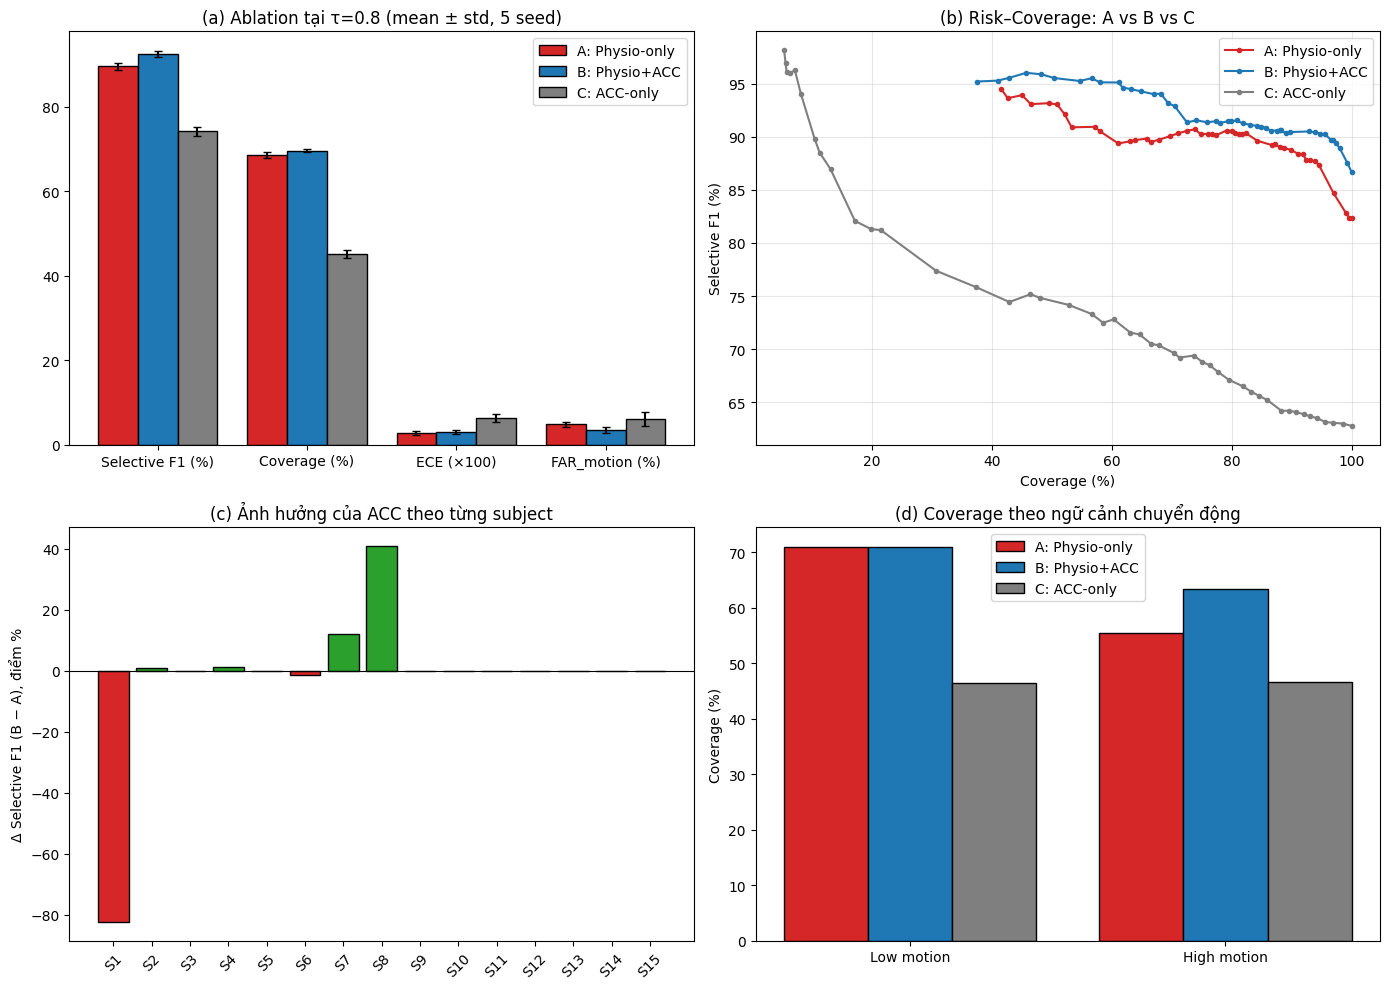

In [8]:
colors = {"A: Physio-only": "#d62728", "B: Physio+ACC": "#1f77b4", "C: ACC-only": "#7f7f7f"}
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# (a) metric chính, mean ± std qua seed
a = ax[0, 0]; mets = [("Sel_F1", "Selective F1 (%)", 100), ("Coverage", "Coverage (%)", 1), ("ECE_sel", "ECE (×100)", 100), ("FAR_sel", "FAR_motion (%)", 1)]
w = 0.8 / len(FEAT_SETS); x = np.arange(len(mets))
for i, cfg in enumerate(FEAT_SETS):
    g_ = per_seed[per_seed.config == cfg]
    m_ = [g_[k].mean() * f for k, _, f in mets]; s_ = [g_[k].std(ddof=1) * f for k, _, f in mets]
    a.bar(x + i*w - 0.4 + w/2, m_, w, yerr=s_, capsize=3, label=cfg, color=colors[cfg], edgecolor="k")
a.set_xticks(x); a.set_xticklabels([m[1] for m in mets]); a.set_title(f"(a) Ablation tại τ={TAU_MAIN} (mean ± std, {len(SEEDS)} seed)"); a.legend()

# (b) Risk-Coverage: A vs B
b = ax[0, 1]
for cfg in FEAT_SETS:
    cov, f1 = [], []
    for t in np.arange(0.50, 0.96, 0.01):
        p = PROBA[(cfg, S0)]; acc = (p >= t) | (1 - p >= t)
        if acc.sum() > 30: cov.append(acc.mean()*100); f1.append(f1_score(y_all[acc], (p[acc] >= t).astype(int))*100)
    b.plot(cov, f1, "o-", ms=3, label=cfg, color=colors[cfg])
b.set_xlabel("Coverage (%)"); b.set_ylabel("Selective F1 (%)"); b.set_title("(b) Risk–Coverage: A vs B vs C"); b.grid(alpha=.3); b.legend()

# (c) ΔSel_F1 theo subject (B − A)
c_ = ax[1, 0]; dF = (B_.Sel_F1 - A.Sel_F1) * 100
c_.bar(SUBJECTS, dF, color=np.where(dF >= 0, "#2ca02c", "#d62728"), edgecolor="k"); c_.axhline(0, c="k", lw=.8)
c_.set_ylabel("Δ Selective F1 (B − A), điểm %"); c_.set_title("(c) Ảnh hưởng của ACC theo từng subject"); c_.tick_params(axis="x", rotation=45)

# (d) Coverage trong Low/High motion
d_ = ax[1, 1]; ctxs = ["Low motion", "High motion"]
for i, cfg in enumerate(FEAT_SETS):
    v = [tab_ctx[(tab_ctx.config == cfg) & (tab_ctx.context == c)].Coverage.values[0] for c in ctxs]
    d_.bar(np.arange(2) + i*w - 0.4 + w/2, v, w, label=cfg, color=colors[cfg], edgecolor="k")
d_.set_xticks(range(2)); d_.set_xticklabels(ctxs); d_.set_ylabel("Coverage (%)"); d_.set_title("(d) Coverage theo ngữ cảnh chuyển động"); d_.legend()

plt.tight_layout(); plt.savefig(f"{OUT}/fig_ablation.png", dpi=200); plt.show()

## 8. Tóm tắt để dán vào báo cáo

In [9]:
g = per_seed.groupby("config")[["Coverage", "Sel_F1", "ECE_sel", "FAR_sel", "Cov_high"]].agg(["mean", "std"])
for cfg in FEAT_SETS:
    r = g.loc[cfg]
    print(f"{cfg:<15} Coverage={r[('Coverage','mean')]:.1f}±{r[('Coverage','std')]:.1f}%  "
          f"SelF1={r[('Sel_F1','mean')]*100:.2f}±{r[('Sel_F1','std')]*100:.2f}%  "
          f"ECE_sel={r[('ECE_sel','mean')]:.4f}  FAR_motion={r[('FAR_sel','mean')]:.2f}±{r[('FAR_sel','std')]:.2f}%  "
          f"Cov(high motion)={r[('Cov_high','mean')]:.1f}%")
print()
print("Paired bootstrap B − A (seed chính), CI chứa 0 = chưa có bằng chứng:")
print(ci.round(4).to_string())

A: Physio-only  Coverage=68.6±0.7%  SelF1=89.61±0.87%  ECE_sel=0.0275  FAR_motion=4.81±0.56%  Cov(high motion)=56.1%
B: Physio+ACC   Coverage=69.6±0.3%  SelF1=92.58±0.67%  ECE_sel=0.0299  FAR_motion=3.46±0.65%  Cov(high motion)=61.8%
C: ACC-only     Coverage=45.1±0.9%  SelF1=74.23±1.11%  ECE_sel=0.0626  FAR_motion=6.10±1.59%  Cov(high motion)=44.0%

Paired bootstrap B − A (seed chính), CI chứa 0 = chưa có bằng chứng:
          diff_B_minus_A  CI95_low  CI95_high  CI_chứa_0
Sel_F1            0.0342   -0.0278     0.1469       True
Coverage          1.5867   -4.7287     7.8334       True
ECE_sel           0.0088   -0.0371     0.0296       True
ECE_full          0.0078   -0.0246     0.0383       True
FAR_sel          -1.0169   -4.5977     1.0870       True
F1_full           0.0436   -0.0052     0.1203       True


## 9. Lưu kết quả lên Google Drive

In [10]:
try:
    from google.colab import drive
    import shutil
    drive.mount("/content/drive")
    DRIVE_DIR = "/content/drive/MyDrive/DSR301m_project_group4/result/Ablation"
    os.makedirs(DRIVE_DIR, exist_ok=True)
    shutil.copytree(OUT, DRIVE_DIR, dirs_exist_ok=True)
    print("Đã lưu vào:", DRIVE_DIR); print(sorted(os.listdir(DRIVE_DIR)))
except ImportError:
    print("Không chạy trên Colab → bỏ qua bước lưu Drive. Kết quả nằm trong thư mục:", OUT)

Mounted at /content/drive
Đã lưu vào: /content/drive/MyDrive/DSR301m_project_group4/result/Ablation
['ablation_bootstrap_diff.csv', 'ablation_main_table.csv', 'ablation_motion_context.csv', 'ablation_per_seed.csv', 'ablation_wilcoxon.csv', 'fig_ablation.png', 'oof_ablation_seed42.csv', 'per_subject_A_vs_B.csv']
